# RSNA breast cancer: subset selection, DICOM to PNG, YOLOX breast ROI (Kaggle, dual T4)

**What this notebook does (and nothing more)**

1. Selects a working subset from `train.csv`: **all positive images** + negatives so the *core* is about **7,000 images**.
2. Splits **by patient (case)**: 70 / 15 / 15, stratified on "patient has any cancer image". All images of one patient stay together.
3. Adds **extra negative patients to val and test only**. The extra amount is computed automatically from a Kaggle disk and time budget (calibrated on real images).
4. Extracts only the selected images: DICOM, then YOLOX breast box, then crop of the raw pixels, DICOM window, PNG (single pass, as in the winner pipeline).
5. Writes `roi_out/{train,val,test}/class_{0,1}/<image_id>.png` and `roi_out/roi_results.csv` (with an `eval_weight` column for prevalence-corrected val/test metrics).

**Before you run**
- Accelerator: **GPU T4 x2**, Internet **ON**.
- Add inputs: the RSNA competition and `dangnh0611/rsna-breast-cancer-detection-best-ckpts`.
- Best way to run: **Save Version, then Save & Run All (Commit)**. It runs unattended and keeps `/kaggle/working` as output.
- Kaggle limits as far as I know (verify on your account): about 12 h per session, about 30 h/week GPU quota, about 20 GB in `/kaggle/working`. The budgets below are in the config cell.

**Safety order:** the 7,000 core images are processed first, the extras last. If the time or disk guard stops the run, the core is already complete.

In [1]:
import os, time, math, shutil
T0 = time.time()   # session clock used by the time guard

if not os.path.isdir("/kaggle/working/mammogram-cancer-classifier"):
    !git clone https://github.com/hassenmohamed-mezr/mammogram-cancer-classifier.git /kaggle/working/mammogram-cancer-classifier
%cd /kaggle/working/mammogram-cancer-classifier
!git pull
!pip -q install pydicom pylibjpeg pylibjpeg-openjpeg pylibjpeg-libjpeg
# if DICOM decoding fails later:  !pip -q install python-gdcm

import torch
NUM_GPUS = torch.cuda.device_count()
print("GPUs:", NUM_GPUS, [torch.cuda.get_device_name(i) for i in range(NUM_GPUS)])
assert NUM_GPUS >= 1, "Turn the GPU accelerator on"
du = shutil.disk_usage("/kaggle/working")
print(f"/kaggle/working: total {du.total/2**30:.1f} GB | free {du.free/2**30:.1f} GB")

Cloning into '/kaggle/working/mammogram-cancer-classifier'...
remote: Enumerating objects: 56, done.
remote: Counting objects: 100% (56/56), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 56 (delta 14), reused 46 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (56/56), 1.09 MiB | 19.96 MiB/s, done.
Resolving deltas: 100% (14/14), done.
/kaggle/working/mammogram-cancer-classifier
Already up to date.
GPUs: 2 ['Tesla T4', 'Tesla T4']
/kaggle/working: total 19.5 GB | free 19.5 GB


### Add YOLOX (winner's breast detector)
Right sidebar, **Add Input**, search `rsna-breast-cancer-detection-best-ckpts` (by dangnh0611), add it. The next cell installs the small dependencies, clones the winner's repo (code only, MIT licence) and finds the checkpoint.

In [2]:
!pip -q install loguru thop pycocotools
WINNER = "/kaggle/working/rsna_winner"
if not os.path.isdir(WINNER):
    !git clone --depth 1 -b reproduce https://github.com/dangnh0611/kaggle_rsna_breast_cancer.git {WINNER}

import glob
hits = glob.glob("/kaggle/input/**/yolox_nano_416_roi_torch.pth", recursive=True)
print("checkpoint:", hits)
assert hits, "Add the best-ckpts dataset as an input (see step above)"
CKPT = hits[0]

Cloning into '/kaggle/working/rsna_winner'...
remote: Enumerating objects: 1768, done.
remote: Counting objects: 100% (1768/1768), done.
remote: Compressing objects: 100% (883/883), done.
remote: Total 1768 (delta 276), reused 1758 (delta 269), pack-reused 0 (from 0)
Receiving objects: 100% (1768/1768), 19.94 MiB | 30.62 MiB/s, done.
Resolving deltas: 100% (276/276), done.
checkpoint: ['/kaggle/input/datasets/dangnh0611/rsna-breast-cancer-detection-best-ckpts/yolox_nano_416_roi_torch.pth']


In [3]:
!ls /kaggle/input
!ls /kaggle/input/competitions/rsna-breast-cancer-detection

competitions  datasets
sample_submission.csv  test.csv  test_images  train.csv  train_images


## Config
Edit paths only if the `ls` above shows different names. Budgets are explained in the comments.

In [4]:
# ---------------- paths ----------------
COMP     = "/kaggle/input/competitions/rsna-breast-cancer-detection"
CSV      = f"{COMP}/train.csv"
IMG_ROOT = f"{COMP}/train_images"
IMG_TMPL = "{root}/{patient_id}/{image_id}.dcm"
WORK        = "/kaggle/working"
OUT         = f"{WORK}/selection"          # selected_manifest.csv + summaries
WORKER_ROOT = f"{WORK}/roi_workers"        # shard manifests, per-GPU outputs, logs
ROI_OUT     = f"{WORK}/roi_out"            # FINAL: split/class folders + roi_results.csv

# ---------------- selection ----------------
SEED         = 42
TARGET_BASE  = 7000              # core size: all positives + negatives, whole patients
SPLIT_FRACS  = (0.70, 0.15, 0.15)  # train / val / test, by patient
EXTRA_MAX    = None              # optional cap on extra val/test negative images (None = budget decides)

# ---------------- Kaggle budget ----------------
MAX_SIDE       = 2048   # longest side of each saved PNG (higher resolution than 1024; native is usually larger)
DISK_BUDGET_GB = 16.0   # planned size of all PNGs (the /kaggle/working limit is about 20 GB)
MIN_FREE_GB    = 1.5    # runtime guard: stop workers if free disk drops below this
TIME_BUDGET_H  = 8.0    # planned extraction wall-clock time
HARD_STOP_H    = 10.0   # runtime guard: stop workers if the whole session passes this (session cap is 12 h)
BATCH_SIZE     = 1000   # execution/checkpoint unit only, NOT a data split
PREFETCH       = 8      # DICOM reader threads per GPU (use 4 if host RAM gets tight)
CALIB_N        = 48     # images used to measure speed and PNG size

## 1. Select the core subset (CPU only, no DICOM is read here)
All positive patients are kept with **all** their images (this includes their negative images, e.g. the other breast). Negative patients are added as whole patients, randomly and proportional to site, until the core reaches about `TARGET_BASE` images. Then a patient-level split is made with `patient_split` from the repo.

In [5]:
import numpy as np, pandas as pd
from pathlib import Path
from src.data import patient_split, check_no_leakage

Path(OUT).mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CSV)
df["path"] = [IMG_TMPL.format(root=IMG_ROOT, patient_id=p, image_id=i)
              for p, i in zip(df["patient_id"], df["image_id"])]
assert df["image_id"].is_unique
assert df.groupby("patient_id")["site_id"].nunique().max() == 1

pat = (df.groupby("patient_id")
         .agg(site_id=("site_id", "first"), n_img=("image_id", "size"),
              has_cancer=("cancer", "max"), n_pos=("cancer", "sum"))
         .reset_index())
pos_pat = pat[pat.has_cancer == 1]
neg_pat = pat[pat.has_cancer == 0]
N_NEG_PAT = len(neg_pat)
print(f"patients: {len(pat):,} | positive patients: {len(pos_pat):,} | negative patients: {N_NEG_PAT:,}")


def take_patients(pool, need, seed):
    # Whole patients, random, proportional to each site's share of the pool. Returns (ids, images_taken).
    chosen, total = [], 0
    shares = pool.groupby("site_id")["n_img"].sum() / pool["n_img"].sum()
    for site, share in shares.items():
        quota, t = int(need * share), 0
        sub = pool[pool.site_id == site].sample(frac=1.0, random_state=seed)
        for pid, n in zip(sub.patient_id, sub.n_img):
            if t == quota:
                break
            if t + n <= quota:
                chosen.append(pid); t += n
        total += t
    left = pool[~pool.patient_id.isin(chosen)].sample(frac=1.0, random_state=seed + 1)
    for pid, n in zip(left.patient_id, left.n_img):   # top-up to the exact target when possible
        if total == need:
            break
        if total + n <= need:
            chosen.append(pid); total += n
    return chosen, total


def shuffle_by_patient(d, seed):
    # Random patient order, all rows of a patient stay contiguous (so every batch mixes classes, patients stay whole).
    ids = d["patient_id"].unique().copy()
    np.random.RandomState(seed).shuffle(ids)
    rank = {p: i for i, p in enumerate(ids)}
    return d.assign(_r=d["patient_id"].map(rank)).sort_values(["_r"], kind="stable").drop(columns="_r").reset_index(drop=True)


need_neg = TARGET_BASE - int(pos_pat["n_img"].sum())
assert need_neg > 0, "TARGET_BASE is smaller than the positive patients' images"
base_neg_ids, got = take_patients(neg_pat, need_neg, SEED)
core_ids = set(pos_pat.patient_id) | set(base_neg_ids)
core = df[df.patient_id.isin(core_ids)].copy()

splits = patient_split(core, SPLIT_FRACS, SEED)          # patient-level, stratified, leakage-checked
core = pd.concat([d.assign(split=n) for n, d in splits.items()], ignore_index=True)
core["priority"] = 0

print(f"core images: {len(core):,} (target {TARGET_BASE:,}) | positives: {int(core.cancer.sum()):,} "
      f"| positive rate {core.cancer.mean():.3%}")
summary = (core.groupby("split")
               .agg(images=("image_id", "size"), patients=("patient_id", "nunique"),
                    pos_images=("cancer", "sum"), pos_rate=("cancer", "mean")))
display(summary)
print("site share, core vs full dataset:")
display(pd.concat([core.site_id.value_counts(normalize=True).rename("core"),
                   df.site_id.value_counts(normalize=True).rename("full")], axis=1))

patients: 11,913 | positive patients: 486 | negative patients: 11,427
core images: 6,999 (target 7,000) | positives: 1,158 | positive rate 16.545%


,images,patients,pos_images,pos_rate
split,,,,
test,1053,229,176,0.167142
train,4878,1064,805,0.165027
val,1068,228,177,0.165730


site share, core vs full dataset:


,core,full
site_id,,
1,0.549507,0.539593
2,0.450493,0.460407


## 2. Preview check (GPU 0)
Check the grid: most titles should say `yolo`, the whole breast must be inside each crop, no inverted images. If many say `otsu` or `full`, stop and look at the grid before spending hours.

preview device: cuda:0


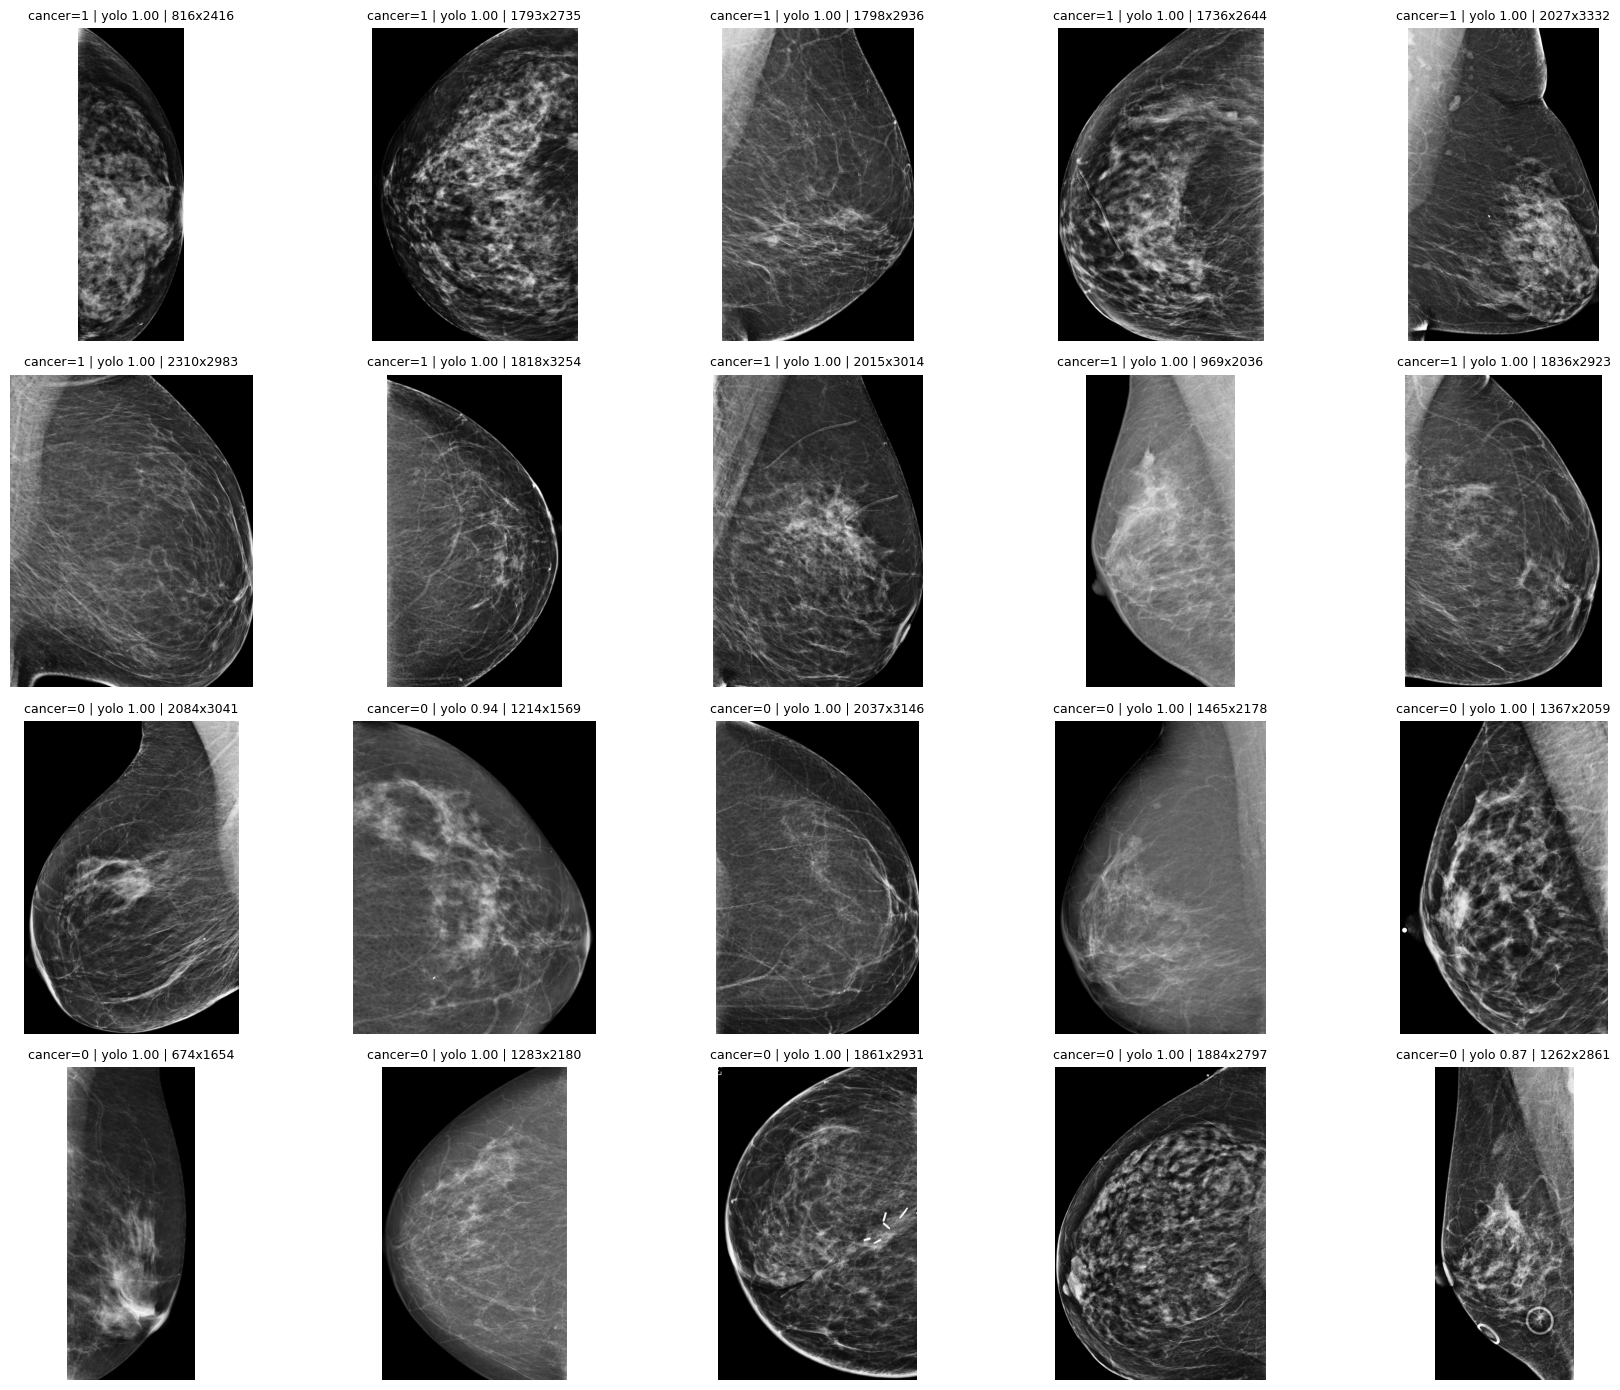

In [6]:
import matplotlib.pyplot as plt
from src.dicom_roi import WinnerRoi, load_dicom, process

roi = WinnerRoi(WINNER, CKPT, device="cuda:0")
print("preview device:", roi.device)

rows = pd.concat([core[core.cancer == 1].sample(10, random_state=1),
                  core[core.cancer == 0].sample(10, random_state=1)])
fig, axes = plt.subplots(4, 5, figsize=(18, 14))
for ax, (_, r) in zip(axes.ravel(), rows.iterrows()):
    crop, info = process(load_dicom(r.path), roi)
    conf = "" if info["conf"] is None else f" {info['conf']:.2f}"
    ax.imshow(crop, cmap="gray"); ax.axis("off")
    ax.set_title(f"cancer={r.cancer} | {info['source']}{conf} | {crop.shape[1]}x{crop.shape[0]}", fontsize=9)
plt.tight_layout(); plt.show()

## 3. Calibrate speed and PNG size on real images, then size the extras
Measures seconds per image (DICOM read + YOLOX + crop + window + resize + PNG encode) and the average PNG size at several resolutions. The number of extra val/test negatives is then the largest that fits **both** the disk budget and the time budget. Time is estimated conservatively (no credit for read/inference overlap, 25% safety margin).

In [7]:
import cv2
from src.run_roi import _resize_long_side

SIDES = sorted(set([1024, 1536, 2048, 3072, MAX_SIDE]))
calib = core.sample(CALIB_N, random_state=SEED)
times, sizes = [], {s: [] for s in SIDES}
for k, (_, r) in enumerate(calib.iterrows()):
    t = time.time()
    crop, info = process(load_dicom(r.path), roi)
    ok, buf = cv2.imencode(".png", _resize_long_side(crop, MAX_SIDE))
    dt = time.time() - t
    if k >= 4:                       # skip warm-up (CUDA init, first reads)
        times.append(dt)
    for s in SIDES:
        ok, b = cv2.imencode(".png", _resize_long_side(crop, s))
        sizes[s].append(len(b) / 2**20)

sec_per_img = float(np.mean(times))
print(f"avg time per image (1 GPU, sequential): {sec_per_img:.2f} s")
print("avg PNG size by MAX_SIDE -> images that fit in the disk budget:")
for s in SIDES:
    mb = float(np.mean(sizes[s])) * 1.10
    print(f"  {s:>5} px: {mb:5.2f} MB/img (incl. 10% margin) -> {int(DISK_BUDGET_GB*1024/mb):,} images"
          + ("   <== MAX_SIDE" if s == MAX_SIDE else ""))

mb_per_img   = float(np.mean(sizes[MAX_SIDE])) * 1.10
wall_per_img = sec_per_img / NUM_GPUS * 1.25
N_time = int(TIME_BUDGET_H * 3600 / wall_per_img)
N_disk = int(DISK_BUDGET_GB * 1024 / mb_per_img)
N_CAP  = min(N_time, N_disk)
print(f"\nimages affordable by time ({TIME_BUDGET_H} h): {N_time:,} | by disk ({DISK_BUDGET_GB} GB): {N_disk:,}"
      f" -> total cap {N_CAP:,} ({'disk' if N_disk <= N_time else 'time'} is the limit)")

del roi
torch.cuda.empty_cache()

avg time per image (1 GPU, sequential): 1.21 s
avg PNG size by MAX_SIDE -> images that fit in the disk budget:
   1024 px:  0.36 MB/img (incl. 10% margin) -> 45,569 images
   1536 px:  0.79 MB/img (incl. 10% margin) -> 20,870 images
   2048 px:  1.37 MB/img (incl. 10% margin) -> 11,942 images   <== MAX_SIDE
   3072 px:  2.74 MB/img (incl. 10% margin) -> 5,977 images

images affordable by time (8.0 h): 38,186 | by disk (16.0 GB): 11,942 -> total cap 11,942 (disk is the limit)


## 4. Add extra negatives to val and test only, build the final manifest
Extra negative patients (whole patients, never used in the core) are split equally between val and test. Train is untouched.

`eval_weight`: val and test are no longer at the natural prevalence. Positive patients' images get weight 1 (they are all included). Negative images from randomly sampled negative patients get weight = (negative patients the split represents) / (negative patients sampled in it), so weighted metrics approximate the natural population (about 2% positive). It is an approximation.

In [8]:
extra_total = max(0, N_CAP - len(core))
if EXTRA_MAX is not None:
    extra_total = min(extra_total, EXTRA_MAX)

pool = neg_pat[~neg_pat.patient_id.isin(set(core.patient_id))]
per_split = extra_total // 2
val_ids,  got_v = take_patients(pool, per_split, SEED + 11)
pool2 = pool[~pool.patient_id.isin(val_ids)]
test_ids, got_t = take_patients(pool2, per_split, SEED + 12)
print(f"extra negatives requested {extra_total:,} | val {got_v:,} images ({len(val_ids)} patients) "
      f"| test {got_t:,} images ({len(test_ids)} patients)")

extras = pd.concat([df[df.patient_id.isin(val_ids)].assign(split="val"),
                    df[df.patient_id.isin(test_ids)].assign(split="test")], ignore_index=True)
extras["priority"] = 1

manifest = pd.concat([shuffle_by_patient(core, SEED), shuffle_by_patient(extras, SEED)], ignore_index=True)

# prevalence-correcting weights for val/test
manifest["eval_weight"] = 1.0
is_pos_patient = manifest.patient_id.isin(set(pos_pat.patient_id))
for s, frac in zip(("val", "test"), SPLIT_FRACS[1:]):
    m = (manifest.split == s) & ~is_pos_patient
    manifest.loc[m, "eval_weight"] = (N_NEG_PAT * frac) / manifest.loc[m, "patient_id"].nunique()

# ---- hard checks
assert manifest.image_id.is_unique
assert int(manifest.cancer.sum()) == int(df.cancer.sum()), "some positive images are missing"
check_no_leakage({s: g for s, g in manifest.groupby("split")})
assert not ((manifest.priority == 1) & (manifest.split == "train")).any(), "extras must be val/test only"

manifest.to_csv(f"{OUT}/selected_manifest.csv", index=False)

final = (manifest.groupby(["split", "priority"])
                 .agg(images=("image_id", "size"), patients=("patient_id", "nunique"),
                      pos_images=("cancer", "sum")))
display(final)
print(f"TOTAL images to extract: {len(manifest):,} | positives: {int(manifest.cancer.sum()):,}")
for s in ("train", "val", "test"):
    g = manifest[manifest.split == s]
    w = g.eval_weight
    print(f"{s:>5}: raw positive rate {g.cancer.mean():.2%} | weighted (approx. natural) {(g.cancer*w).sum()/w.sum():.2%}")

extra negatives requested 4,943 | val 2,469 images (535 patients) | test 2,470 images (530 patients)


images  patients  pos_images
split priority                              
test  0           1053       229         176
      1           2470       530           0
train 0           4878      1064         805
val   0           1068       228         177
      1           2469       535           0

TOTAL images to extract: 11,938 | positives: 1,158
train: raw positive rate 16.50% | weighted (approx. natural) 16.50%
  val: raw positive rate 5.00% | weighted (approx. natural) 2.14%
 test: raw positive rate 5.00% | weighted (approx. natural) 2.12%


## 5. Prepare shards (execution units only)
The manifest order is: core first, extras last. It is cut into sequential batches of about `BATCH_SIZE`; each batch is interleaved across the GPUs. Nothing here changes the train/val/test assignment.

In [9]:
import math, time, shutil, glob, subprocess, sys   # restart-safe: needs only the setup + config cells above
import numpy as np, pandas as pd
from pathlib import Path

manifest = pd.read_csv(f"{OUT}/selected_manifest.csv")      # re-readable after a kernel restart
WORKER_ROOT = Path(WORKER_ROOT); WORKER_ROOT.mkdir(parents=True, exist_ok=True)
NUM_BATCHES = math.ceil(len(manifest) / BATCH_SIZE)
index_batches = np.array_split(np.arange(len(manifest)), NUM_BATCHES)

for b, idx in enumerate(index_batches, start=1):
    d = WORKER_ROOT / f"batch_{b:02d}"; d.mkdir(parents=True, exist_ok=True)
    part = manifest.iloc[idx].reset_index(drop=True)
    for g in range(NUM_GPUS):
        part.iloc[g::NUM_GPUS].to_csv(d / f"gpu{g}_manifest.csv", index=False)

n_rows = sum(len(pd.read_csv(f)) for f in WORKER_ROOT.glob("batch_*/gpu*_manifest.csv"))
assert n_rows == len(manifest), (n_rows, len(manifest))
print(f"{NUM_BATCHES} batches x {NUM_GPUS} GPU shards cover all {n_rows:,} manifest rows exactly once")

12 batches x 2 GPU shards cover all 11,938 manifest rows exactly once


## 6. Extraction: one persistent worker per GPU
Each worker loads YOLOX once and runs all its shards through the repo's resumable `run()`. If the session dies, re-run the setup, checkpoint and config cells, then section 5 and this cell; finished images are skipped. The monitor stops the workers if the time or the disk guard is hit (extras are last, so the core stays complete).

In [ ]:
WORKER_SCRIPT = "/kaggle/working/run_roi_gpu_worker.py"
Path(WORKER_SCRIPT).write_text(r'''import argparse, sys, torch
from pathlib import Path

sys.path.insert(0, "/kaggle/working/mammogram-cancer-classifier")
from src.dicom_roi import WinnerRoi
from src.run_roi import run

ap = argparse.ArgumentParser()
ap.add_argument("--gpu", type=int, required=True)
ap.add_argument("--root", required=True)
ap.add_argument("--winner", required=True)
ap.add_argument("--checkpoint", required=True)
ap.add_argument("--num-batches", type=int, required=True)
ap.add_argument("--prefetch", type=int, default=8)
ap.add_argument("--max-side", type=int, default=2048)
a = ap.parse_args()

torch.cuda.set_device(a.gpu)
roi = WinnerRoi(a.winner, a.checkpoint, device=f"cuda:{a.gpu}")
print(f"[GPU {a.gpu}] model ready on {roi.device}", flush=True)
root = Path(a.root)
for b in range(1, a.num_batches + 1):
    name = f"batch_{b:02d}"
    print(f"[GPU {a.gpu}] starting {name}", flush=True)
    run(str(root / name / f"gpu{a.gpu}_manifest.csv"), str(root / name / f"gpu{a.gpu}_output"),
        roi=roi, max_side=a.max_side, prefetch=a.prefetch, flush_every=200)
    print(f"[GPU {a.gpu}] completed {name}", flush=True)
''', encoding="utf-8")

import subprocess, sys, glob

def rows_done():
    c = 0
    for f in glob.glob(f"{WORKER_ROOT}/batch_*/gpu*_output/roi_results.csv"):
        with open(f) as fh:
            c += max(sum(1 for _ in fh) - 1, 0)
    return c

TOTAL = len(manifest)
procs = []
for g in range(NUM_GPUS):
    log = open(WORKER_ROOT / f"gpu{g}.log", "a", buffering=1)
    p = subprocess.Popen(
        [sys.executable, WORKER_SCRIPT, "--gpu", str(g), "--root", str(WORKER_ROOT),
         "--winner", WINNER, "--checkpoint", CKPT, "--num-batches", str(NUM_BATCHES),
         "--prefetch", str(PREFETCH), "--max-side", str(MAX_SIDE)],
        cwd="/kaggle/working/mammogram-cancer-classifier", stdout=log, stderr=subprocess.STDOUT)
    procs.append((g, p, log))
    print(f"started GPU {g} worker, PID={p.pid}")

start, last_print, stopped_by_guard = time.time(), 0.0, None
d0 = rows_done()                      # rows already finished in an earlier run (resume)
while any(p.poll() is None for _, p, _ in procs):
    time.sleep(30)
    free_gb = shutil.disk_usage("/kaggle/working").free / 2**30
    if time.time() - last_print >= 300:
        d = rows_done(); el = time.time() - start
        rate = (d - d0) / el if el > 0 else 0
        eta = (TOTAL - d) / rate / 60 if rate > 0 else float("nan")
        print(f"{d:,}/{TOTAL:,} done | {rate:.2f} img/s | elapsed {el/60:.0f} min | eta {eta:.0f} min | free disk {free_gb:.1f} GB", flush=True)
        last_print = time.time()
    if time.time() - T0 > HARD_STOP_H * 3600:
        stopped_by_guard = f"session time passed {HARD_STOP_H} h"
    elif free_gb < MIN_FREE_GB:
        stopped_by_guard = f"free disk below {MIN_FREE_GB} GB"
    if stopped_by_guard:
        print("GUARD:", stopped_by_guard, "-> stopping workers (extras are last; check the core in the merge cell)")
        for _, p, _ in procs:
            if p.poll() is None:
                p.terminate()
        break

failed = []
for g, p, log in procs:
    rc = p.wait(); log.close()
    print(f"GPU {g} worker exit code: {rc}")
    if rc != 0 and not stopped_by_guard:
        failed.append(g)
print(f"rows done: {rows_done():,}/{TOTAL:,}")
if failed:
    raise RuntimeError(f"GPU worker(s) {failed} failed. Read {WORKER_ROOT}/gpu*.log, then re-run this cell (it resumes).")

started GPU 0 worker, PID=205
started GPU 1 worker, PID=206
0/11,938 done | 0.00 img/s | elapsed 1 min | eta nan min | free disk 19.4 GB
400/11,938 done | 1.21 img/s | elapsed 6 min | eta 159 min | free disk 18.7 GB
995/11,938 done | 1.58 img/s | elapsed 11 min | eta 115 min | free disk 18.0 GB
1,795/11,938 done | 1.93 img/s | elapsed 16 min | eta 88 min | free disk 17.3 GB
2,390/11,938 done | 1.94 img/s | elapsed 21 min | eta 82 min | free disk 16.7 GB
2,985/11,938 done | 1.95 img/s | elapsed 26 min | eta 76 min | free disk 16.0 GB


## 7. Merge into `roi_out/{split}/class_{0,1}/` and verify
Files are **moved** (not copied), so there is no extra disk use. Safe to re-run. The core must be complete: every core image is either extracted or listed in `roi_errors.csv`.

In [ ]:
import cv2, matplotlib.pyplot as plt
import numpy as np, pandas as pd
from src.data import check_no_leakage

manifest = pd.read_csv(f"{OUT}/selected_manifest.csv")
WORKER_ROOT = Path(WORKER_ROOT)
roi_root = Path(ROI_OUT); roi_root.mkdir(parents=True, exist_ok=True)

parts, err_parts, missing = [], [], []
for out_dir in sorted(WORKER_ROOT.glob("batch_*/gpu*_output")):
    rp = out_dir / "roi_results.csv"
    if not rp.exists():
        missing.append(str(rp)); continue
    part = pd.read_csv(rp).merge(manifest[["image_id", "split"]], on="image_id", how="left")
    new_paths = []
    for r in part.itertuples(index=False):
        dest_dir = roi_root / r.split / f"class_{int(r.cancer)}"
        dest_dir.mkdir(parents=True, exist_ok=True)
        dest, src = dest_dir / f"{r.image_id}.png", Path(r.roi_path)
        if src.exists():
            if dest.exists(): src.unlink()
            else: shutil.move(str(src), str(dest))
        elif not dest.exists():
            raise FileNotFoundError(f"ROI file missing in both places: {src}")
        new_paths.append(str(dest))
    part["roi_path"] = new_paths
    parts.append(part)
    ep = out_dir / "roi_errors.csv"
    if ep.exists():
        err_parts.append(pd.read_csv(ep))
    try: (out_dir / "crops").rmdir()      # only removes it if empty
    except OSError: pass

results = pd.concat(parts, ignore_index=True).drop_duplicates(subset=["image_id"], keep="last")
errors = (pd.concat(err_parts, ignore_index=True).drop_duplicates(subset=["image_id"], keep="last")
          if err_parts else pd.DataFrame(columns=["image_id"]))

core_all = set(manifest.loc[manifest.priority == 0, "image_id"])
done_ids, err_ids = set(results.image_id), set(errors.image_id) - set(results.image_id)
unfinished_core = core_all - done_ids - err_ids
assert not unfinished_core, f"{len(unfinished_core)} core images were neither extracted nor reported as errors; re-run section 6"

keep_cols = ["image_id"] + [c for c in manifest.columns if c not in results.columns]
results = results.merge(manifest[keep_cols], on="image_id", how="left")
results.to_csv(roi_root / "roi_results.csv", index=False)
if len(errors):
    errors.to_csv(roi_root / "roi_errors.csv", index=False)

extras_all = set(manifest.loc[manifest.priority == 1, "image_id"])
print(f"extracted: {len(results):,} / selected {len(manifest):,} | errors: {len(errors):,} "
      f"| extras not processed: {len(extras_all - done_ids - err_ids):,} | missing outputs: {len(missing)}")
print("\nimages per split x class:")
display(pd.crosstab(results.split, results.cancer))
print("ROI source (yolo is what you want):")
display(results.source.value_counts().to_frame("images").assign(share=lambda d: (d.images / d.images.sum()).round(4)))
for s in ("train", "val", "test"):
    g = results[results.split == s]
    if len(g):
        print(f"{s:>5}: raw positive rate {g.cancer.mean():.2%} | weighted (approx. natural) {(g.cancer*g.eval_weight).sum()/g.eval_weight.sum():.2%}")
print(f"\nno patient in two splits: ", end="")
check_no_leakage({s: g for s, g in results.groupby("split")}); print("OK")
!du -sh {ROI_OUT}

In [ ]:
# Final visual check: random finished crops from every split
samp = pd.concat([g.sample(min(4, len(g)), random_state=3) for _, g in results.groupby("split")])
fig, axes = plt.subplots(3, 4, figsize=(16, 14))
for ax, (_, r) in zip(axes.ravel(), samp.iterrows()):
    im = cv2.imread(r.roi_path, cv2.IMREAD_GRAYSCALE)
    ax.imshow(im, cmap="gray"); ax.axis("off")
    ax.set_title(f"{r.split} | cancer={r.cancer} | {r.source} | {im.shape[1]}x{im.shape[0]}", fontsize=9)
plt.tight_layout(); plt.show()

## 8. (Optional) Pack each split/class into one uncompressed tar
PNG does not compress further, so `tar` is only for having a few big files instead of thousands of small ones in the Kaggle output. `--remove-files` deletes the PNGs as they are packed, so the peak disk use stays small. Leave `PACK = False` unless you want it. After packing, `roi_path` in `roi_results.csv` no longer points to loose files.

In [ ]:
PACK = False
if PACK:
    for d in sorted(Path(ROI_OUT).glob("*/class_*")):
        tar_path = Path(ROI_OUT) / f"{d.parent.name}_{d.name}.tar"
        !tar -cf {tar_path} -C {d} . --remove-files
        shutil.rmtree(d, ignore_errors=True)
        print("packed", tar_path)
    !du -sh {ROI_OUT}

## How to use the outputs
- Train from `roi_out/train/class_{0,1}`, validate on `val`, report on `test`.
- `roi_results.csv` has `split`, `cancer`, `roi_path`, `source`, `conf`, `box`, `orig_h/w`, `eval_weight` and the original `train.csv` columns (`site_id`, `view`, `laterality`, `density`, `machine_id`, ...).
- Prevalence-corrected metrics on val/test (approximate), for example:
  `roc_auc_score(y, p, sample_weight=w)` and `average_precision_score(y, p, sample_weight=w)` with `w = eval_weight`. Pick the decision threshold on weighted val, not on raw val.
- After the run: save `/kaggle/working/roi_out` as a Kaggle Dataset (Output tab, New Dataset).

In [ ]:
odd = results[results.source != "yolo"]
print(odd[["image_id", "split", "cancer", "source"]].to_string())